<span style="font-family: Times New Roman; font-size: 30px; font-weight: bold;">
A Brain Network Exploration Through Random Network Models
</span>

<br> <!-- Agrega un salto de línea -->

<span style="font-family: Times New Roman; font-size: 24px;">
Advanced Data Analysis (PHYS 605) Final Project.
</span>

<br> <!-- Agrega un salto de línea -->

<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
Random Network vs Real Brain Network
</span>

In [1]:
#Importing Libraries 

import pandas as pd #Data frame Libraries 
import networkx as nx #Network Library
import matplotlib.pyplot as plt #Plotting Library
import numpy as np #Numpy Library
import seaborn as sns #Fancy Plotting Library
from scipy.stats import binom #Binomial distribution
from scipy.stats import poisson #Poisson distribution
import powerlaw


<span style="font-family: Times New Roman; font-size: 24px;">
Generating and studying the G(N,p) Random Network
</span>

<br> <!-- Agrega un salto de línea -->

<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
The random network that we are going to generate is known as the model G(N,p), where you have a fixed value of the couple of nodes and you add the edges following a probability of p≤1 of having an edge in an specific couple of nodes. G(N, p) model in which the probability of having a link between two nodes is equal to p < 1.
</span>
    
<br> <!-- Agrega un salto de línea -->

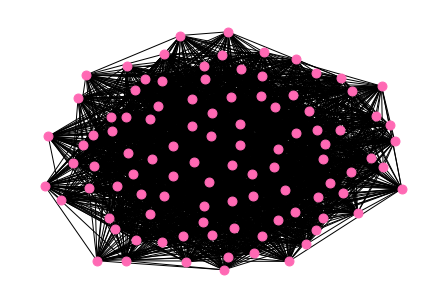

In [2]:
#Generating an G(N,p) Random Network for analysis

#Function to generate the COUPLE of nodes following the probability given
def random_edges(N, p):
    for i in range(N):
        for j in range(i): #By both fors go through all the possible nodes 
            if np.random.rand() < p: #If a random number btwn 0 and 1 is less than the probability p
                yield i,j            #Then add the couple of linked nodes

#Function to generate the random network                
def random_Network(N, p):
    G = nx.Graph() #Creating the Network environment
    G.add_nodes_from(range(N)) #Add the N nodes to the Network previously created
  
    G.add_edges_from( random_edges(N, p) ) #Add the edges restricted by the probability p
  
    return G

#Example of the Network with 100 nodes and an edge probability of 0.2
N = 100
p = 0.5
G = random_Network(N,p)
#Drawing the Network
nx.draw(G, node_size=80 , node_color='#FF69B4' , node_shape='o' )



In [3]:
N = 100
p = 0.5
G = random_Network(N,p)
rshort_path_length = nx.average_shortest_path_length(G)

print('The average shortest path length is:\t\t', rshort_path_length)

The average shortest path length is:		 1.5056565656565657


In [4]:
#SPOILER
#Lets see the path length of a random network 
N1 = 9119
p1 =  0.00184
G1 = random_Network(N1,p1)


<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
The degree distribution for an Erdos-Renyi random Network can be appproached to a Binomial distribution...
</span>
    
<br> <!-- Agrega un salto de línea -->

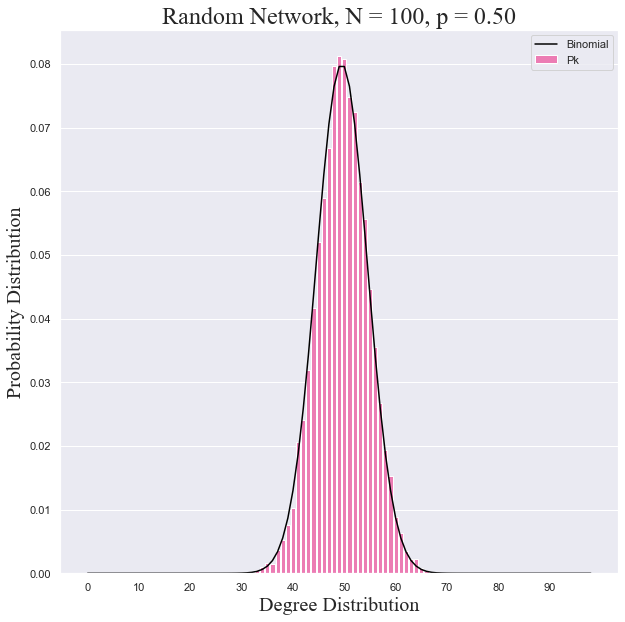

In [5]:
#Binomial degree distribution
sns.set() #Style
#Create a figure and select its size
plt.figure(figsize=(10, 10))

runnings = 100

#Creating an array of zeros 
Y = np.zeros(N-1)


for i in range(runnings): #Multiple runnings to create the ensemble
    
    #Generating the random Network
    G = random_Network(N,p) 
    
    #[dict(G.degree)[i] for i in G]: We have a dictionary that contains the degrees for a node i
    #bins = range(N): The degree can only go from 0 to N-1
    #density = True: Without this we will only have the number of nodes with k degree,
    #but when we add it we normalize the histogram transforming it into a probability dist.
    #Thus, with this we change it into a probability distribution Pk=Nk/N
    y, x = np.histogram([dict(G.degree)[i] for i in G], bins = range(N), density = True)
    
    Y += y #Summing all the histograms generated in every running
    
Y = Y/runnings #Diviing them over the number of runnings

#For the histogram
sns.barplot(x=x[:-1], y=Y, color='#FF69B4', label='Pk')

#Comparing our distribution to verify if it fits with the Biniomial Probability Mass Function
plt.plot(x[:-1], binom.pmf(x[:-1],N-1,p), 'black', label = 'Binomial')

#Title and labels of the plot              
plt.xlabel('k', size = 20)
font_name = "Times New Roman" 
#plt.title('Random Network, N = %i, p = %1.2f' %(N,p), size = 20)
plt.xlabel('Degree Distribution', fontsize=20, fontname=font_name)
plt.ylabel('Probability Distribution', fontsize=20, fontname=font_name)
plt.title('Random Network, N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.legend()

selected_ticks = np.arange(min(x[:-1]), max(x[:-1])+1, 10)  #Every ten values
plt.xticks(selected_ticks)

#Show the plot     
plt.show()

<br> <!-- Agrega un salto de línea -->
<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
The probability distribution could be appproach to a Poisson distribution when....
</span>
    
<br> <!-- Agrega un salto de línea -->

Text(0, 0.5, 'Probability Mass Function (k)')

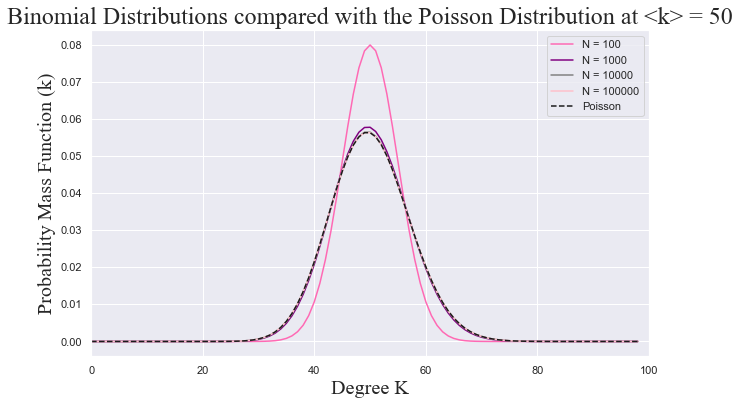

In [6]:
#Different binomial distributions to approach into a Poission

k = 50 #Choosing a value of k less than the length of the Network
x = np.arange(100)

sns.set()
#Create a figure and select its size
plt.figure(figsize=(10, 6))

#Choosing the colors I will use
colores = ['#FF69B4', 'purple', 'grey', 'pink']

#We will select 4 N´s of 4 magnitud orders
for i,N in enumerate([10**2, 10**3, 10**4, 10**5]):
    
    p = k/(N-1) #probability of linking

    plt.plot(x[:-1],binom.pmf(x[:-1], N-1, p), label = 'N = '+str(N), color=colores[i]) #Plot binomials

    
#Limiting the x-axis values
plt.xlim([0,100])

#Plotting the Poisson distribution
plt.plot(x[:-1], poisson.pmf(x[:-1], 50), 'k--', label = 'Poisson')

#Selecting Times new Roman as font for the plot writtens
font_name = "Times New Roman" 

#Plotting
plt.legend()
plt.title('Binomial Distributions compared with the Poisson Distribution at <k> = 50', fontsize=24, fontname=font_name)
plt.xlabel('Degree K', fontsize=20, fontname=font_name)
plt.ylabel('Probability Mass Function (k)', fontsize=20, fontname=font_name)

<br> <!-- Agrega un salto de línea -->

<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
Now let´s see what happens with the clustering coefficients....
</span>
    
<br> <!-- Agrega un salto de línea -->

The average clustering coefficient is:
 0.48694195425547027
The probability of linking is:
 0.5


Text(0, 0.5, 'Clustering coefficient')

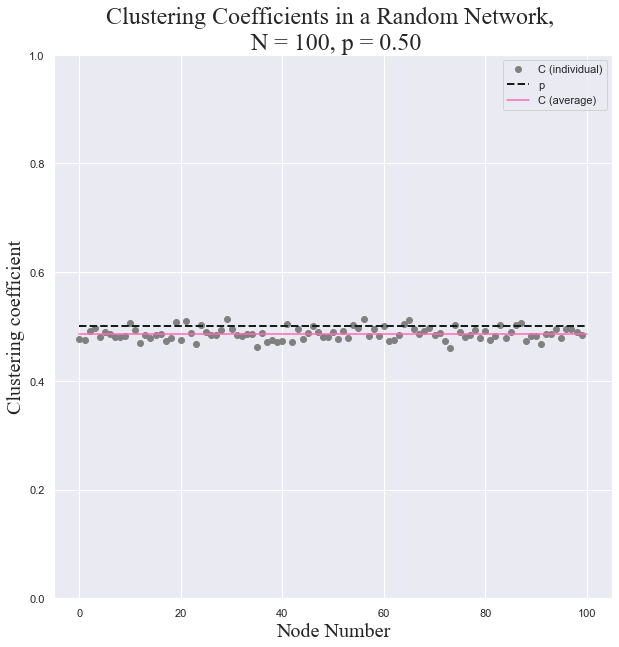

In [7]:
#Showing how the clustering coefficients matches with the linking probability

#Giving the same properties than before to our random Network
N=100 
p=.5

#Generating the Network
G = random_Network(N,p)

#Computing the average clustering coefficient
C = nx.average_clustering(G)

#Showing values
print('The average clustering coefficient is:\n', C)
print('The probability of linking is:\n', p)

#Saving the dictionary
diccionario = nx.clustering(G)
Y = [diccionario[i] for i in G]

#Plotting 
plt.figure(figsize = [10,10])
plt.plot(Y, 'o', color="grey", label = 'C (individual)') #Plotting each node CC individualy
plt.plot([0,N], [p,p], 'k--', linewidth = 2, label = 'p') #Plotting the probability p 
plt.plot([0,N], [C,C],'-', color="#FF69B4", label = 'C (average)') #Plotting the average value
plt.ylim([0,1])
plt.legend()
plt.xlabel

#Title and labels
plt.title('Clustering Coefficients in a Random Network, \n N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Node Number', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient', fontsize=20, fontname=font_name)

<span style="font-family: Times New Roman; font-size: 24px;">
Real Brain Netwrok
</span>

<br> <!-- Agrega un salto de línea -->

<span style="font-family: Times New Roman; font-size: 20px; font-weight: italics;">
Let´s analyse the Network Data obtained from the Network Data Repository from the Bejing Normal University....
</span>
    
<br> <!-- Agrega un salto de línea -->

In [8]:
#Importing the dataset
df0 = pd.read_csv("bn-human-BNU_1_0025864_session_1-bg.edges",
                  header= None,
                  sep=" ")

In [9]:
#Giving name to the columns
df0.columns = ['node1', 'node2']
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143158339 entries, 0 to 143158338
Data columns (total 2 columns):
 #   Column  Dtype
---  ------  -----
 0   node1   int64
 1   node2   int64
dtypes: int64(2)
memory usage: 2.1 GB


In [10]:
#Limiting the number of nodes (taking a sample)
df = df0[(df0["node1"] <= 50000) & (df0["node2"] <= 50000)]
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 76614 entries, 0 to 735029
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   node1   76614 non-null  int64
 1   node2   76614 non-null  int64
dtypes: int64(2)
memory usage: 1.8 MB


In [11]:
#Let´s see how our dataset looks
df.head()

,node1,node2
0,2,256
1,2,285
2,2,313
3,6,7
4,6,312


In [12]:
#Generating netwrok from the edges list given
G = nx.from_pandas_edgelist(df,
                            source = "node1",
                            target = "node2")

In [14]:
#General properties

N = len(G) #Number of Nodes
L = len(G.edges)  #Number of edges
k = 2*L/N #Average degree
C = nx.average_clustering(G) #The average clustering coefficient


p = k / (N-1) #The clustering coefficient that the network would have if it were random 

print('General properties of the Network:')
print('- The number of nodes is:\t', N)
print('- The number of edges is:\t', L)
print('- The average degree is:\t\t', k)



General properties of the Network:
- The number of nodes is:	 9119
- The number of edges is:	 76614
- The average degree is:		 16.803158241035202


In [15]:
#Generating the dictionaries

grado_dict = dict(nx.degree(G)) #Creating a dictionary of the degrees of the network
clustering_dict = nx.clustering(G) #Creating a dictionary with the clustering coefficients

In [16]:
#Generating a data frame with the degree and clustering of each node

df1 = pd.DataFrame([grado_dict, clustering_dict]).T #Writting this above as a dataframe
df1.columns = ['Degree', 'Clustering']
df1.head()

,Degree,Clustering
2,3.0,1.000000
256,16.0,0.383333
285,15.0,0.352381
313,7.0,0.619048
6,4.0,1.000000


In [17]:
#Let this give us the maximum degree of the node
K = df1.Degree.max() 

Text(0, 0.5, 'Probability Mass Distribution')

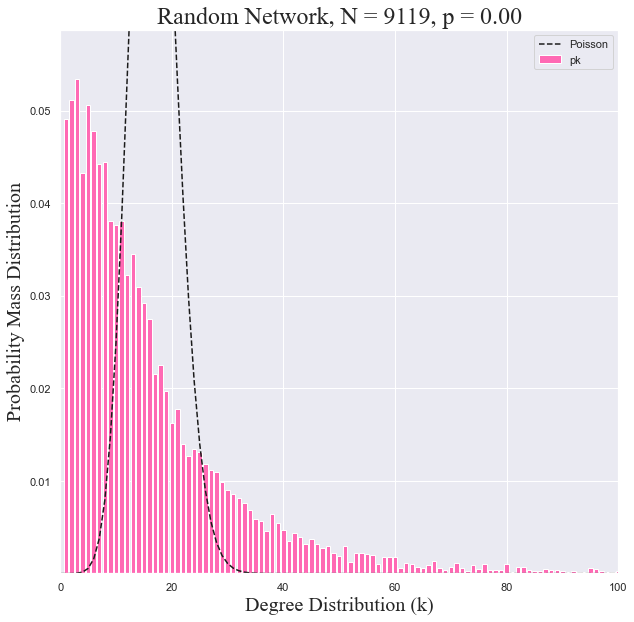

In [18]:
#A histogram to compare to our random Network

y0,x0 = np.histogram(df1.Degree.values, bins = range(int(K)+1), density= True) #We arrange the degree values as a histogram

plt.figure(figsize = [10,10])  #Size
plt.bar(x0[:-1], y0, label = 'pk', color='#FF69B4') #Barplot
plt.plot(x0[:-1], poisson.pmf(x0[:-1], k), color='k',  linestyle='--', label = 'Poisson') #Plotting Poisson

plt.ylim([0.5*y0[y0>0].min(),1.1*y0.max()]) #Limiting the y-axis
plt.xlim([0,100])
plt.legend()
plt.title('Random Network, N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Degree Distribution (k)', fontsize = 20, fontname=font_name)
plt.ylabel('Probability Mass Distribution', fontsize = 20, fontname=font_name)

Text(0, 0.5, 'Probability Mass Function (PMF)')

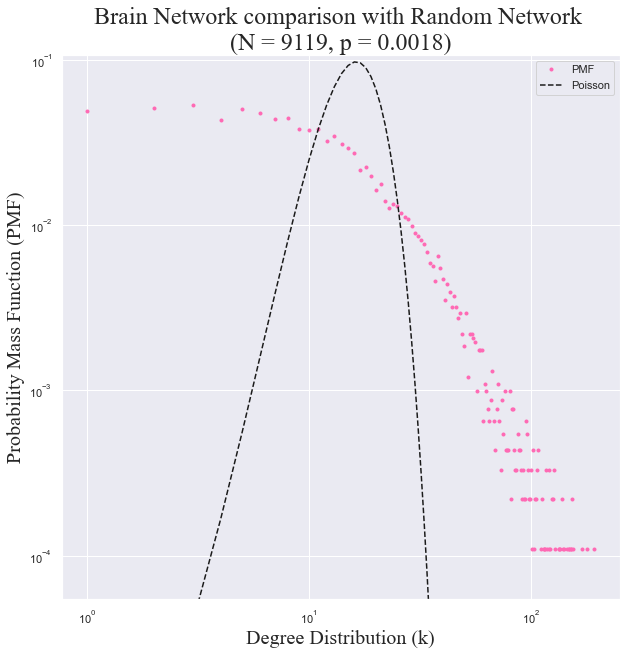

In [19]:
#Degree distribution in logaritmic-logaritmic scale

plt.figure(figsize = [10,10])
plt.plot(x0[:-1], y0, '.', label = 'PMF', color='#FF69B4')
plt.plot(x0[:-1], poisson.pmf(x0[:-1], k), 'k--', label = 'Poisson')

#Applying loh to both axis
plt.xscale('log')
plt.yscale('log')

#Looking better, like before
plt.ylim([0.5*y0[y0>0].min(),2*y0.max()])
plt.legend()


plt.title('Brain Network comparison with Random Network \n(N = %i, p = %.4f)' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Degree Distribution (k)', fontsize = 20, fontname=font_name)
plt.ylabel('Probability Mass Function (PMF)', fontsize = 20, fontname=font_name)


Text(0, 0.5, 'Probability Distribution Function (PDF)')

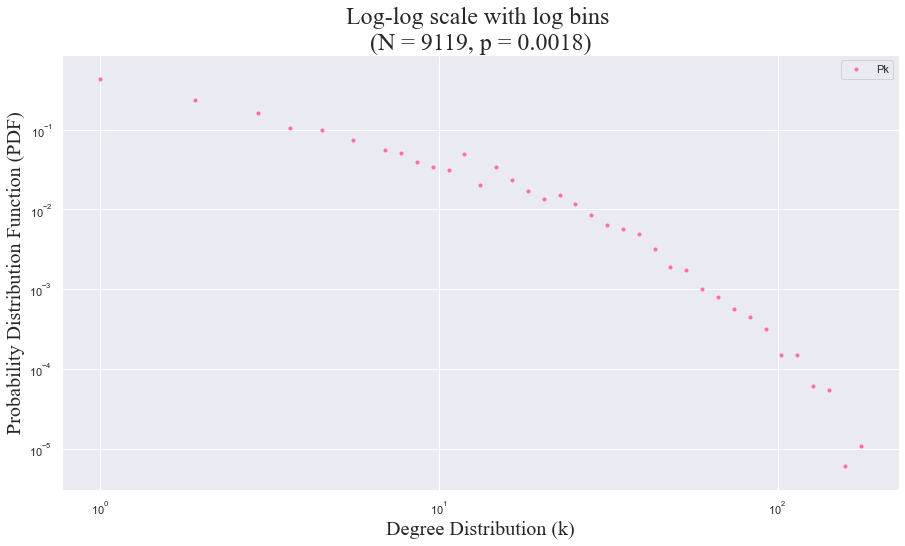

In [20]:
#Changing from PDF to PMF

#Log with logaritmic values
y,x = np.histogram(df1.Degree.values, bins = np.logspace(0, np.log10(K+2)), density= True) #We arrange the degree values as a histogram

plt.figure(figsize = [15,8])
plt.plot(x[:-1], y, '.', label = 'Pk', color='#FF69B4')

#Log scale
plt.xscale('log')
plt.yscale('log')

#Looking better, like before
plt.ylim([0.5*y[y>0].min(),2*y.max()])
plt.legend()

plt.title('Log-log scale with log bins \n(N = %i, p = %.4f)' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Degree Distribution (k)', fontsize = 20, fontname=font_name)
plt.ylabel('Probability Distribution Function (PDF)', fontsize = 20, fontname=font_name)

In [21]:
#Power law library usage

#For writting less
Degree = df1.Degree.values

fit = powerlaw.Fit(Degree)

print("The value of alpha is:", fit.alpha)
print("The value of minimum k is:", fit.xmin)

Calculating best minimal value for power law fit
The value of alpha is: 3.5861319272872305
The value of minimum k is: 36.0


Text(0, 0.5, 'Probability Distribution Function (PDF)')

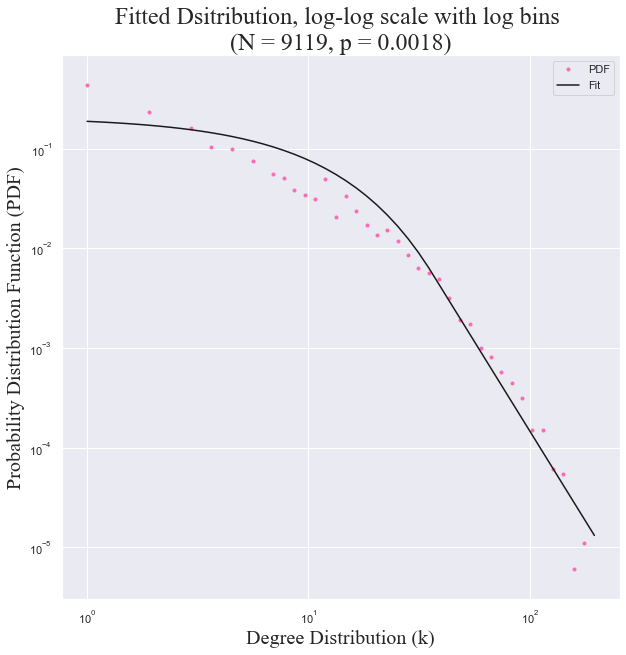

In [22]:
plt.figure(figsize = [10,10])
plt.plot(x[:-1], y, '.', label = 'PDF', color='#FF69B4')

c_valor = 0.08*((fit.alpha-1)/fit.xmin)

#First function, x >= fit.xmin
funcion1 = (x >= fit.xmin) * c_valor*(x/fit.xmin)**(-fit.alpha)

#Second function, x < fit.xmin
funcion2 = (x < fit.xmin) * c_valor*np.exp(-fit.alpha * (-1 + x/fit.xmin))

#Combining both functions using numpy.where
resultado = np.where(x >= fit.xmin, funcion1, funcion2)

#Plot both logscale
plt.plot(x, resultado, color='k', label = 'Fit')
plt.xscale('log')
plt.yscale('log')

#Well looking
plt.ylim([0.5*y[y>0].min(),2*y.max()])
plt.legend()

plt.title('Fitted Dsitribution, log-log scale with log bins \n(N = %i, p = %.4f)' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Degree Distribution (k)', fontsize = 20, fontname=font_name)
plt.ylabel('Probability Distribution Function (PDF)', fontsize = 20, fontname=font_name)


In [25]:
#Testing how good is our model for a power law and an exponential 

#Fitting power law libray
fit = powerlaw.Fit(df1.Degree.values)

#Printing the KS test
print(fit.distribution_compare('power_law', 'exponential'))

Calculating best minimal value for power law fit
(2.0383175419829014, 0.8071685417440119)


Text(0, 0.5, 'Clustering coefficient')

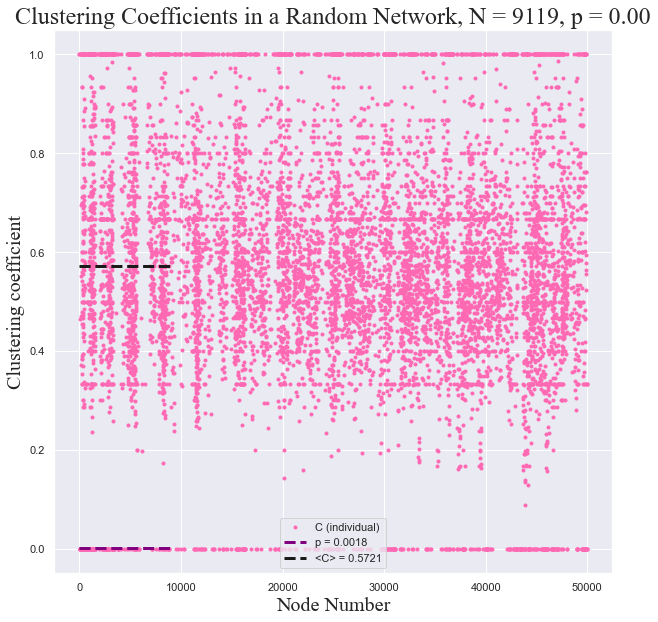

In [26]:
#Plotting the clustering coefficients with the order of the nodes made a mess, just as we did before with the random one

plt.figure(figsize = [10,10])
Y= df1.Clustering #Obtaining the clustering column
plt.plot(Y, '.', color="#FF69B4", label = 'C (individual)') #Individual cluster

#Plotting
plt.plot([0,N], [p,p], '--', linewidth = 3, label = 'p = %.4f' %p , color="purple")
plt.plot([0,N], [C,C], 'k--', linewidth = 3, label = '<C> = %.4f' %C)
plt.legend()

plt.title('Clustering Coefficients in a Random Network, N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Node Number', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient', fontsize=20, fontname=font_name)

Text(0, 0.5, 'Clustering coefficient')

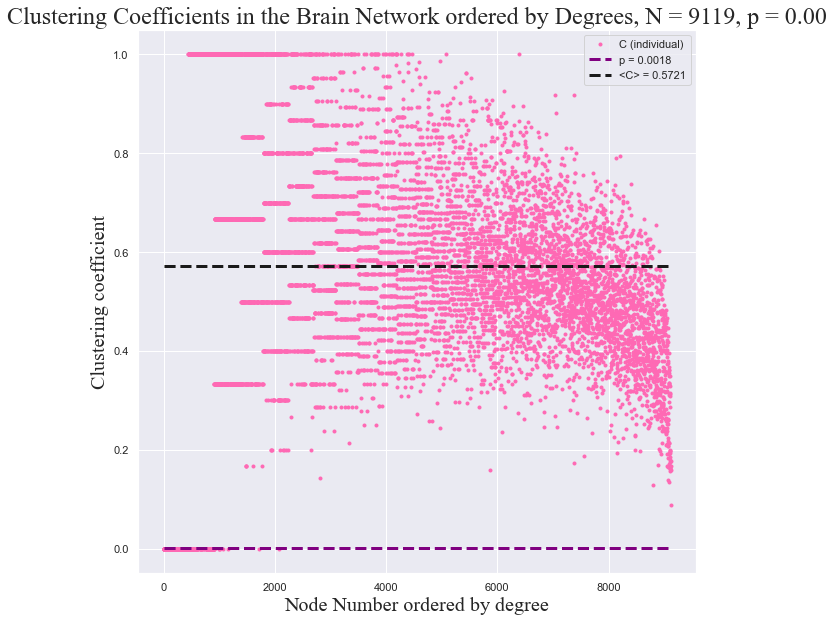

In [27]:
#Clustering coefficients ordered by degree

plt.figure(figsize = [10,10])
Y=df1.sort_values('Degree').reset_index().Clustering#.plot(style = 'b.', alpha = .4)
plt.plot(Y, '.', color="#FF69B4", label = 'C (individual)')

plt.plot([0,N], [p,p], '--', linewidth = 3, label = 'p = %.4f' %p , color="purple")
plt.plot([0,N], [C,C], 'k--', linewidth = 3, label = '<C> = %.4f' %C)

plt.legend()

plt.title('Clustering Coefficients in the Brain Network ordered by Degrees, N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Node Number ordered by degree', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient', fontsize=20, fontname=font_name)

Text(0, 0.5, 'Clustering coefficient')

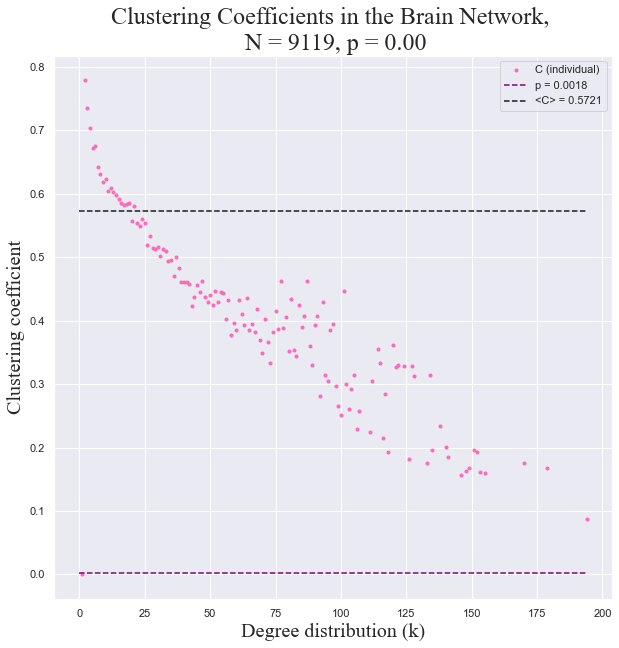

In [28]:
#Clustering coefficients vs degree distribution

X, Y = df1.groupby('Degree')['Clustering'].mean().reset_index().values.T
plt.figure(figsize=[10,10])
plt.plot(X, Y, '.', color="#FF69B4", label = 'C (individual)')

plt.plot([0,K], [p,p], '--', label = 'p = %.4f' %p, color="purple")
plt.plot([0,K], [C,C], 'k--', label = '<C> = %.4f' %C)

plt.xlabel('k', size = 20)
plt.ylabel('C(k)', size = 20)
plt.legend()

plt.title('Clustering Coefficients in the Brain Network, \n N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Degree distribution (k)', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient', fontsize=20, fontname=font_name)

Text(0, 0.5, 'Clustering coefficient * Degree')

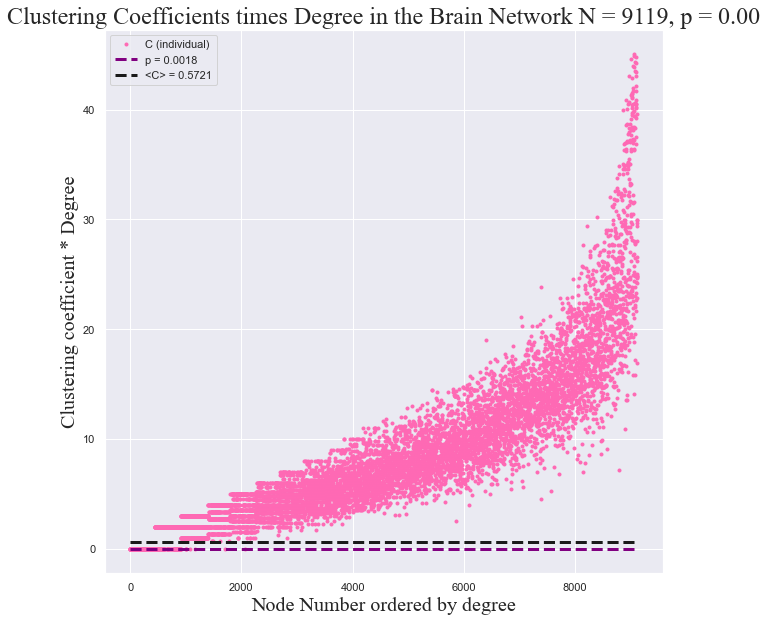

In [29]:
#Obtaining the degree times the clustering to see if it give us information about the linking

#Multiplication
df1['Clustering_Degree'] = df1['Clustering'] * df1['Degree']

plt.figure(figsize = [10,10])
Y=df1.sort_values('Degree').reset_index().Clustering_Degree#.plot(style = 'b.', alpha = .4)
plt.plot(Y, '.', color="#FF69B4", label = 'C (individual)')

plt.plot([0,N], [p,p], '--', linewidth = 3, label = 'p = %.4f' %p , color="purple")
plt.plot([0,N], [C,C], 'k--', linewidth = 3, label = '<C> = %.4f' %C)

plt.legend()

plt.title('Clustering Coefficients times Degree in the Brain Network N = %i, p = %1.2f' %(N,p), fontsize=24, fontname=font_name)
plt.xlabel('Node Number ordered by degree', fontsize=20, fontname=font_name)
plt.ylabel('Clustering coefficient * Degree', fontsize=20, fontname=font_name)